# 02 · Exploratory Data Analysis

**Goal:** understand the target, find which features relate to a made attempt, and spot what needs
scaling, binning or dropping before modeling.

The EDA runs on the **attempt-level table** built by `src/clean.py`: IPF-affiliated meets, one row per squat, bench or deadlift attempt.
Every feature uses only information known **before** the attempt (the lifter's profile, their earlier meets, and earlier attempts at this meet).

Only tools from the course are used: pandas, numpy, matplotlib and seaborn.

In [1]:
import sys
sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from clean import load_attempts, load_raw

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

attempts = load_attempts()          # first run builds data/attempts_ipf.pkl (about 2 minutes)
overall = attempts['made'].mean()
print(attempts.shape, f'overall make rate = {overall:.1%}')
attempts.head()

(6486914, 28) overall make rate = 75.4%


,lifter_id,Date,Sex,Equipment,Event,Age,BodyweightKg,Federation,n_prior_meets,days_since_last,...,misses_earlier_lifts,prev_best,jump_pct,pct_prev_best,weight_to_bw,year,pct_best_bin,jump_bin,meet_country,tested
0,1,2026-05-15,F,Raw,SBD,14.0,74.199997,PI,0,NaN,...,0,NaN,NaN,NaN,0.943396,2026,no history,first attempt,Other,Yes
1,2,2012-03-26,M,Single-ply,SBD,23.5,74.000000,KPF,0,NaN,...,0,NaN,NaN,NaN,1.891892,2012,no history,first attempt,Other,Yes
2,4,2017-12-04,F,Raw,SBD,16.5,71.099998,AsianPF,0,NaN,...,0,NaN,NaN,NaN,1.441632,2017,no history,first attempt,Other,Yes
3,6,1991-09-05,M,Single-ply,SBD,34.5,74.300003,FPR,0,NaN,...,0,NaN,NaN,NaN,2.960969,1991,no history,first attempt,Other,Yes
4,12,2012-05-01,M,Single-ply,SBD,16.5,81.699997,AsianPF,0,NaN,...,0,NaN,NaN,NaN,1.835985,2012,no history,first attempt,Other,Yes


## 1. What is the target and what does it represent?

**`made`** = 1 if the attempt was successful (a "good lift": at least 2 of the 3 referees gave a white light), 0 if it was missed.
In the raw file a missed attempt is stored as a negative weight, so the label comes directly from the official results, with no manual labeling.

Each row is one attempt. A full-power lifter has up to 9 rows per meet (3 lifts × 3 attempts).

In [2]:
print(f"{len(attempts):,} attempts | {attempts['lifter_id'].nunique():,} lifters | "
      f"{attempts.groupby(['lifter_id', 'Date']).ngroups:,} lifter-meets")
attempts.groupby('lift', observed=True).size().rename('attempts')

6,486,914 attempts | 290,346 lifters | 911,505 lifter-meets


lift
Bench       2625269
Deadlift    1942242
Squat       1919403
Name: attempts, dtype: int64

## 2. Is the target categorical or continuous? Is it balanced?

        attempts     %
made                  
made     4892338  75.4
missed   1594576  24.6


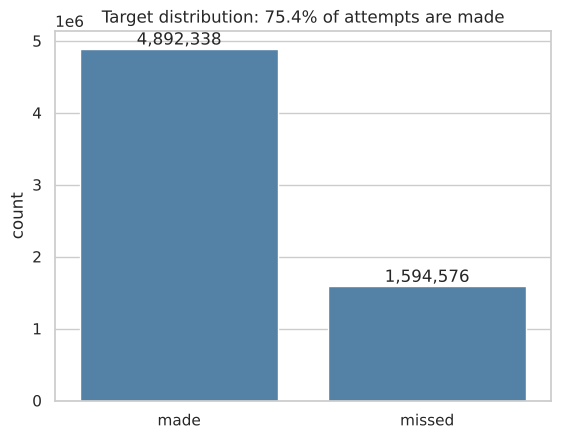

A model that always predicts 'made' is 75.4% accurate but never warns about a miss.


In [3]:
counts = attempts['made'].value_counts().rename({1: 'made', 0: 'missed'})
print(pd.concat([counts, (counts / len(attempts) * 100).round(1)], axis=1, keys=['attempts', '%']))

ax = sns.countplot(x=attempts['made'].map({1: 'made', 0: 'missed'}), order=['made', 'missed'], color='steelblue')
ax.bar_label(ax.containers[0], fmt='{:,.0f}')
ax.set_title(f'Target distribution: {overall:.1%} of attempts are made')
ax.set_xlabel('')
plt.show()

print(f"A model that always predicts 'made' is {overall:.1%} accurate but never warns about a miss.")

**Binary and moderately imbalanced:** about 3 made attempts for every miss. Accuracy alone is misleading, so we will use
ROC-AUC, balanced accuracy and recall / precision for the **missed** class (the attempts a lifter or evaluator needs to be warned about).

## 3. What types of features do we have?

In [4]:
numeric = ['weight', 'weight_to_bw', 'pct_prev_best', 'jump_kg', 'jump_pct', 'Age', 'BodyweightKg',
           'n_prior_meets', 'days_since_last', 'prior_make_rate', 'attempt_no', 'misses_this_lift', 'misses_earlier_lifts']
categorical = ['lift', 'prev_result', 'Sex', 'Equipment', 'Event', 'tested', 'meet_country', 'Federation']
print(f'{len(numeric)} numeric candidate features   :', numeric)
print(f'{len(categorical)} categorical candidate features:', categorical)

13 numeric candidate features   : ['weight', 'weight_to_bw', 'pct_prev_best', 'jump_kg', 'jump_pct', 'Age', 'BodyweightKg', 'n_prior_meets', 'days_since_last', 'prior_make_rate', 'attempt_no', 'misses_this_lift', 'misses_earlier_lifts']
8 categorical candidate features: ['lift', 'prev_result', 'Sex', 'Equipment', 'Event', 'tested', 'meet_country', 'Federation']


| Group | Features |
| --- | --- |
| The attempt | `lift`, `attempt_no`, `weight`, `weight_to_bw` (weight ÷ bodyweight) |
| Earlier attempts at this meet | `prev_result` (none / made / missed), `jump_kg`, `jump_pct`, `misses_this_lift`, `misses_earlier_lifts` (e.g. squat misses before bench) |
| Lifter history (earlier meets) | `prev_best` → `pct_prev_best` (weight as % of best at earlier meets), `n_prior_meets`, `days_since_last`, `prior_make_rate` |
| Lifter profile | `Sex`, `Age`, `BodyweightKg`, `Equipment`, `tested` |
| Meet | `Event`, `meet_country` (top 15 + Other), `Federation` |

## 4. How many null values does each feature have?

In [5]:
null_share = (attempts[numeric + categorical].isna().mean() * 100).round(1).sort_values(ascending=False)
null_share[null_share > 0].to_frame('null_%')

,null_%
jump_pct,34.0
jump_kg,34.0
prior_make_rate,31.0
pct_prev_best,28.0
days_since_last,26.5
Age,15.7
weight_to_bw,0.1
BodyweightKg,0.1


In [6]:
first_meet = attempts['n_prior_meets'] == 0
print(f'Attempts by lifters at their first meet: {first_meet.mean():.1%}')
print(f'Make rate, first meet vs later meets  : {attempts.loc[first_meet, "made"].mean():.1%} vs {attempts.loc[~first_meet, "made"].mean():.1%}')

Attempts by lifters at their first meet: 26.5%


Make rate, first meet vs later meets  : 75.8% vs 75.3%


The nulls are **structural, not errors**:
- `jump_kg` / `jump_pct` are empty for every **first attempt** (there is no previous attempt).
- `pct_prev_best`, `days_since_last`, `prior_make_rate` are empty for lifters at their **first meet** (no history).
- `Age` is not reported by every federation.

So missing values get the median **plus a 0/1 "was missing" flag** (`SimpleImputer(add_indicator=True)`, lesson 13), and the linear model gets bins with their own "first attempt" / "no history" level.

## 5. Numeric features: distributions, skew and outliers

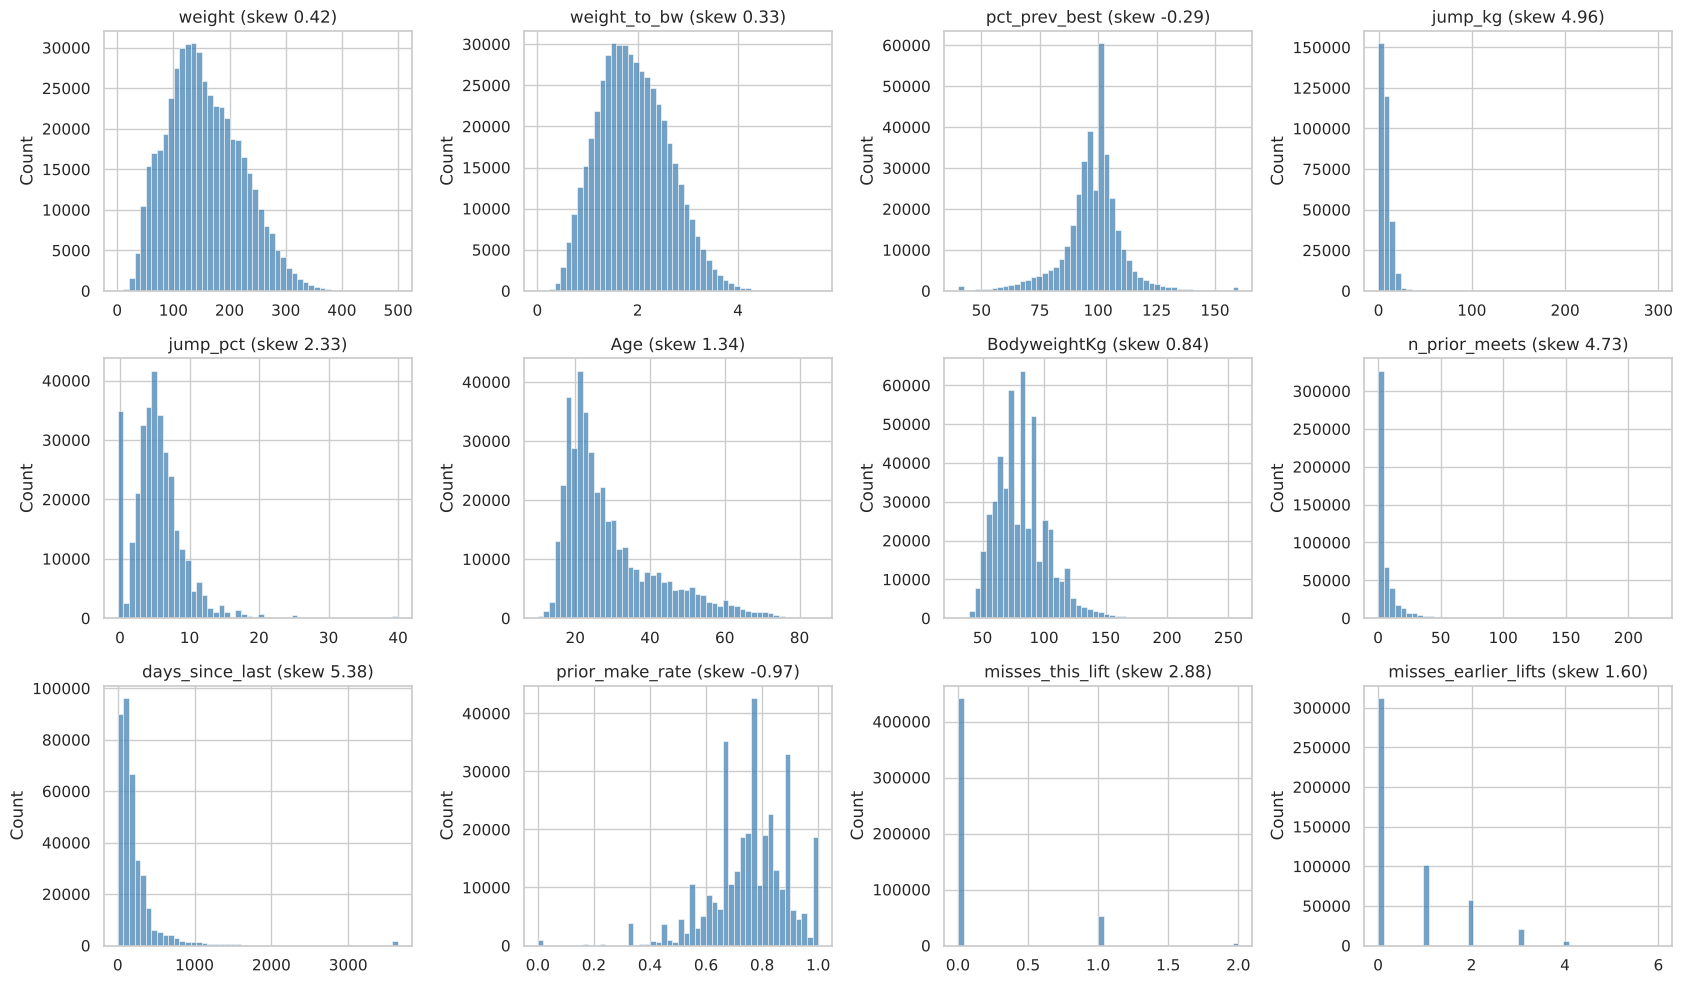

In [7]:
sample = attempts.sample(500_000, random_state=42)
fig, axes = plt.subplots(3, 4, figsize=(17, 10))
for ax, col in zip(axes.flat, [c for c in numeric if c not in ['attempt_no']]):
    sns.histplot(sample[col].dropna(), bins=50, ax=ax, color='steelblue')
    ax.set_title(f'{col} (skew {sample[col].skew():.2f})')
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

In [8]:
def iqr_outliers(s):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100

summary = pd.DataFrame({
    'skew': attempts[numeric].skew().round(2),
    'outlier_%': [round(iqr_outliers(attempts[c]), 1) for c in numeric],
    'median_made': attempts.loc[attempts['made'] == 1, numeric].median(),
    'median_missed': attempts.loc[attempts['made'] == 0, numeric].median(),
})
summary

,skew,outlier_%,median_made,median_missed
weight,0.42,0.4,147.500000,152.500000
weight_to_bw,0.33,0.4,1.855288,1.908024
pct_prev_best,-0.30,8.6,97.297302,101.600006
jump_kg,4.61,4.5,7.500000,5.000000
jump_pct,2.32,3.5,5.344828,4.166667
Age,1.35,4.9,24.500000,25.000000
BodyweightKg,0.84,2.2,80.800003,80.599998
n_prior_meets,4.76,9.6,2.000000,2.000000
days_since_last,5.38,8.3,142.000000,140.000000
prior_make_rate,-0.97,1.8,0.777778,0.740741


- `n_prior_meets` and `days_since_last` are strongly right-skewed: a few lifters have 100+ meets or long breaks. The IQR outliers are real lifters, so they are kept (trees handle them; values were already capped at fixed limits in `src/clean.py`).
- `jump_pct` and `pct_prev_best` were capped at fixed limits (−20% to +40% and 40% to 160%) to remove data-entry errors.
- **Missed attempts are heavier relative to the lifter's earlier best** (median `pct_prev_best` above) and come after **smaller jumps**: see sections 6 and 9.

## 6. Make rate across bins of the numeric features

Binning shows **non-linear** patterns that a straight correlation misses.

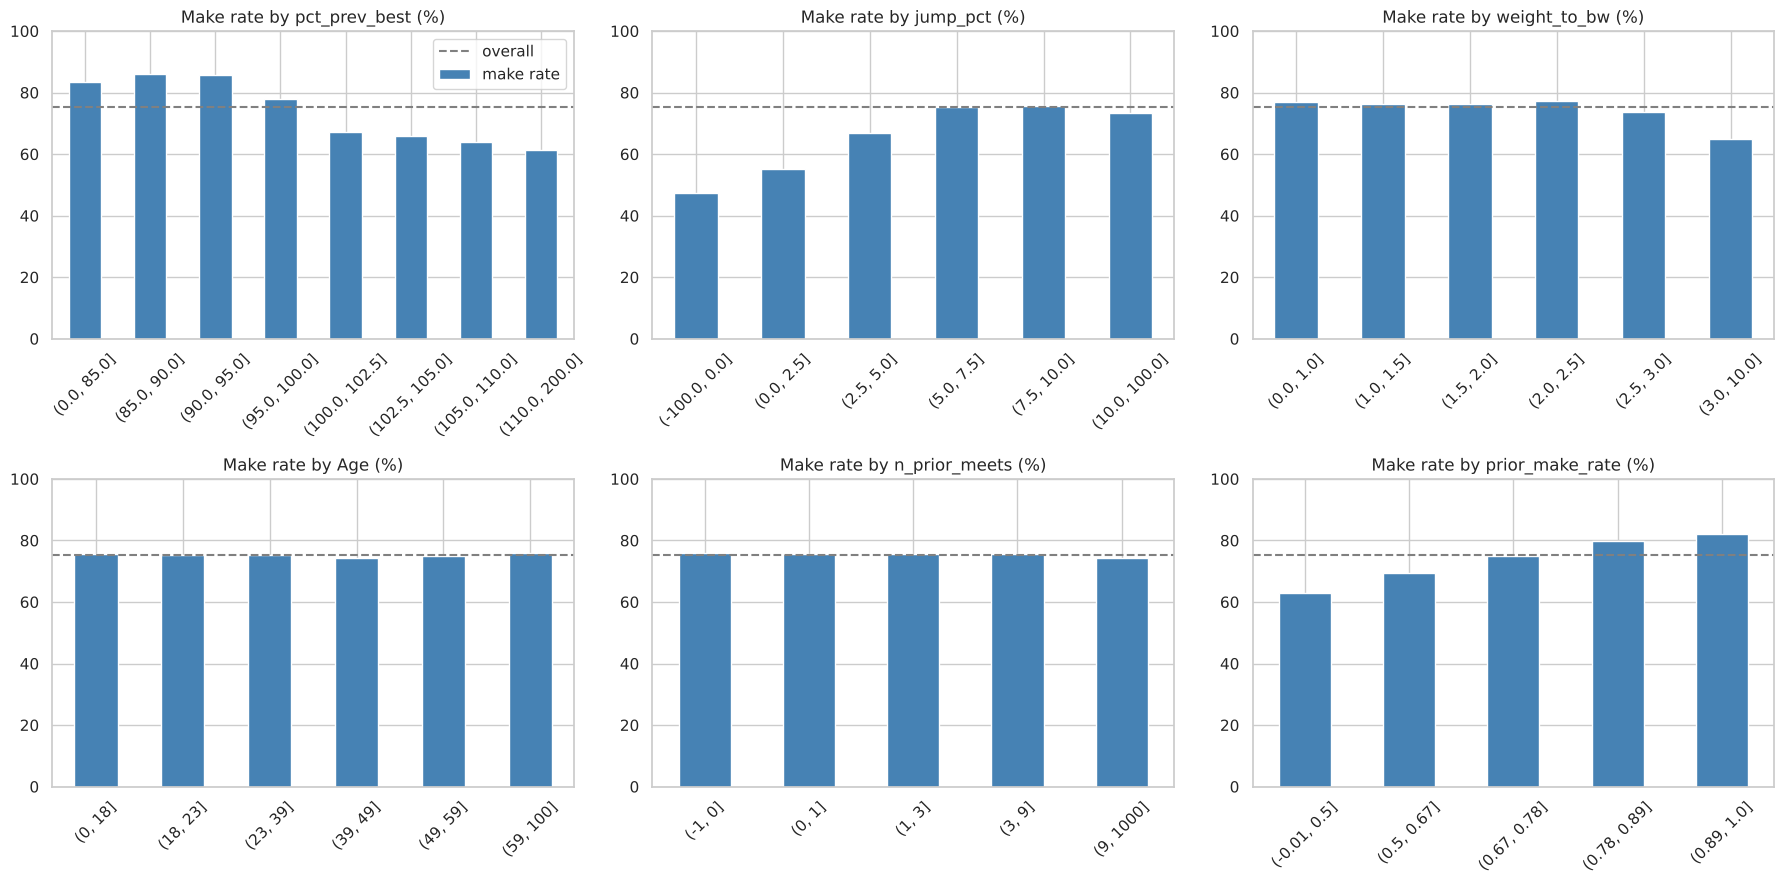

                  count   mean
pct_prev_best                 
(0.0, 85.0]      554470  0.834
(85.0, 90.0]     340200  0.860
(90.0, 95.0]     723759  0.859
(95.0, 100.0]   1271729  0.780
(100.0, 102.5]   385513  0.672
(102.5, 105.0]   445581  0.658
(105.0, 110.0]   481751  0.638
(110.0, 200.0]   467560  0.614 

                 count   mean
jump_pct                     
(-100.0, 0.0]   456013  0.473
(0.0, 2.5]      338328  0.552
(2.5, 5.0]     1388845  0.669
(5.0, 7.5]     1198402  0.754
(7.5, 10.0]     556183  0.758
(10.0, 100.0]   346206  0.734 



                count   mean
weight_to_bw                
(0.0, 1.0]     586922  0.768
(1.0, 1.5]    1384514  0.763
(1.5, 2.0]    1702931  0.764
(2.0, 2.5]    1448585  0.773
(2.5, 3.0]     900230  0.736
(3.0, 10.0]    457661  0.649 

             count   mean
Age                      
(0, 18]     825076  0.754
(18, 23]   1546760  0.754
(23, 39]   2028187  0.753
(39, 49]    544305  0.744
(49, 59]    316553  0.750
(59, 100]   206888  0.761 



                 count   mean
n_prior_meets                
(-1, 0]        1717292  0.758
(0, 1]          984352  0.754
(1, 3]         1164193  0.757
(3, 9]         1395869  0.756
(9, 1000]      1225208  0.744 

                   count   mean
prior_make_rate                
(-0.01, 0.5]      218795  0.630
(0.5, 0.67]       997244  0.694
(0.67, 0.78]     1379751  0.750
(0.78, 0.89]     1380269  0.799
(0.89, 1.0]       499443  0.822 



In [9]:
bins = {
    'pct_prev_best': pd.cut(attempts['pct_prev_best'], [0, 85, 90, 95, 100, 102.5, 105, 110, 200]),
    'jump_pct': pd.cut(attempts['jump_pct'], [-100, 0, 2.5, 5, 7.5, 10, 100]),
    'weight_to_bw': pd.cut(attempts['weight_to_bw'], [0, 1, 1.5, 2, 2.5, 3, 10]),
    'Age': pd.cut(attempts['Age'], [0, 18, 23, 39, 49, 59, 100]),
    'n_prior_meets': pd.cut(attempts['n_prior_meets'], [-1, 0, 1, 3, 9, 1000]),
    'prior_make_rate': pd.cut(attempts['prior_make_rate'], [-0.01, 0.5, 0.67, 0.78, 0.89, 1]),
}
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, (name, b) in zip(axes.flat, bins.items()):
    rate = attempts.groupby(b, observed=True)['made'].mean() * 100
    rate.plot(kind='bar', ax=ax, color='steelblue', label='make rate')
    ax.axhline(overall * 100, color='grey', ls='--', label='overall')
    ax.set_title(f'Make rate by {name} (%)')
    ax.set_xlabel('')
    ax.set_ylim(0, 100)
    ax.tick_params(axis='x', rotation=45)
axes.flat[0].legend()
plt.tight_layout()
plt.show()

for name, b in bins.items():
    print(attempts.groupby(b, observed=True)['made'].agg(['count', 'mean']).round(3), '\n')

- **`pct_prev_best` is the strongest numeric signal, and it is not a straight line:** 83–86% of attempts below 95% of the lifter's earlier best are made, 78.0% at 95–100%, then the rate **drops to 67.2% just above the old best** (100–102.5%) and 61.4% at 110%+. → fixed bins for the linear model.
- **`jump_pct`:** repeating the same weight or going lower (mostly after a miss) is made only 47.3% of the time, tiny jumps (0–2.5%) 55.2%, normal jumps (5–10%) 75–76%. Also non-linear → bins.
- **`weight_to_bw`** is flat (76–77%) up to 2.5× bodyweight and falls to 64.9% above 3×.
- **`prior_make_rate`** matters: lifters who made half or fewer of their attempts at earlier meets make 63.0% now, against 82.2% for those above 89%.
- **`Age`** (74.4–76.1%) and **`n_prior_meets`** (74.4–75.8%) are almost flat on their own.

## 7. Categorical features vs the target

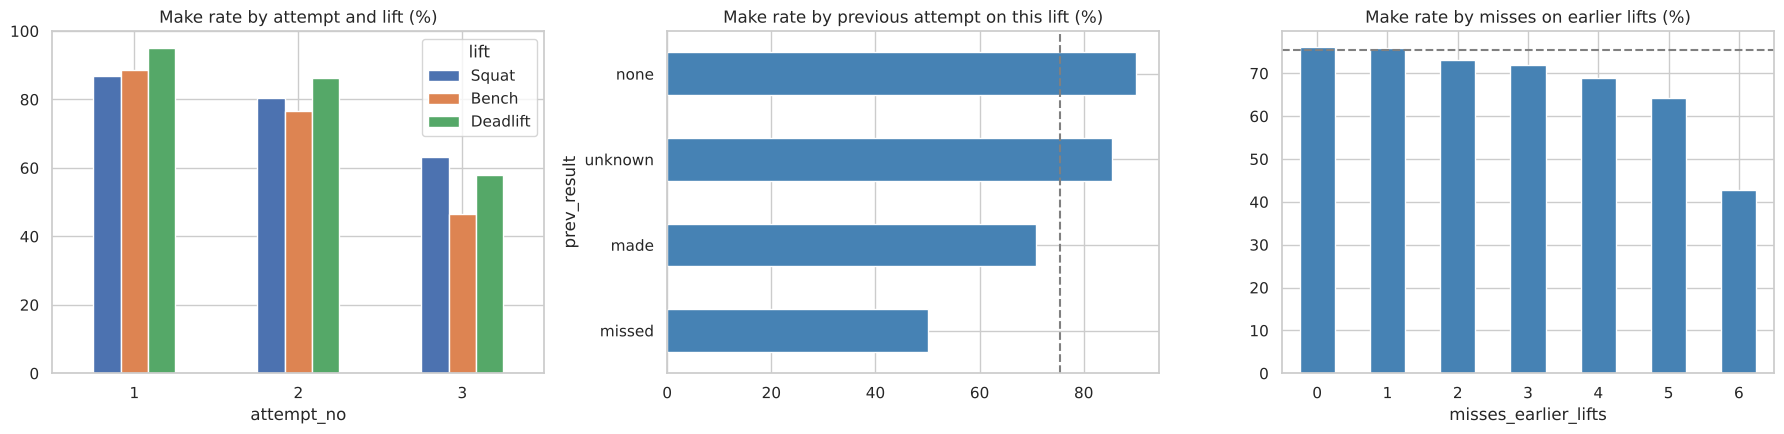

lift,Bench,Deadlift,Squat
attempt_no,,,
1,88.7,94.9,86.7
2,76.8,86.3,80.6
3,46.5,57.9,63.1


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
lift_att = attempts.groupby(['attempt_no', 'lift'], observed=True)['made'].mean().unstack() * 100
lift_att[['Squat', 'Bench', 'Deadlift']].plot(kind='bar', ax=axes[0], rot=0)
axes[0].set_title('Make rate by attempt and lift (%)'); axes[0].set_ylim(0, 100)

(attempts.groupby('prev_result', observed=True)['made'].mean() * 100).sort_values().plot(kind='barh', ax=axes[1], color='steelblue')
axes[1].axvline(overall * 100, color='grey', ls='--'); axes[1].set_title('Make rate by previous attempt on this lift (%)')

(attempts.groupby('misses_earlier_lifts')['made'].mean() * 100).plot(kind='bar', ax=axes[2], color='steelblue', rot=0)
axes[2].axhline(overall * 100, color='grey', ls='--'); axes[2].set_title('Make rate by misses on earlier lifts (%)')
plt.tight_layout(); plt.show()
lift_att.round(1)

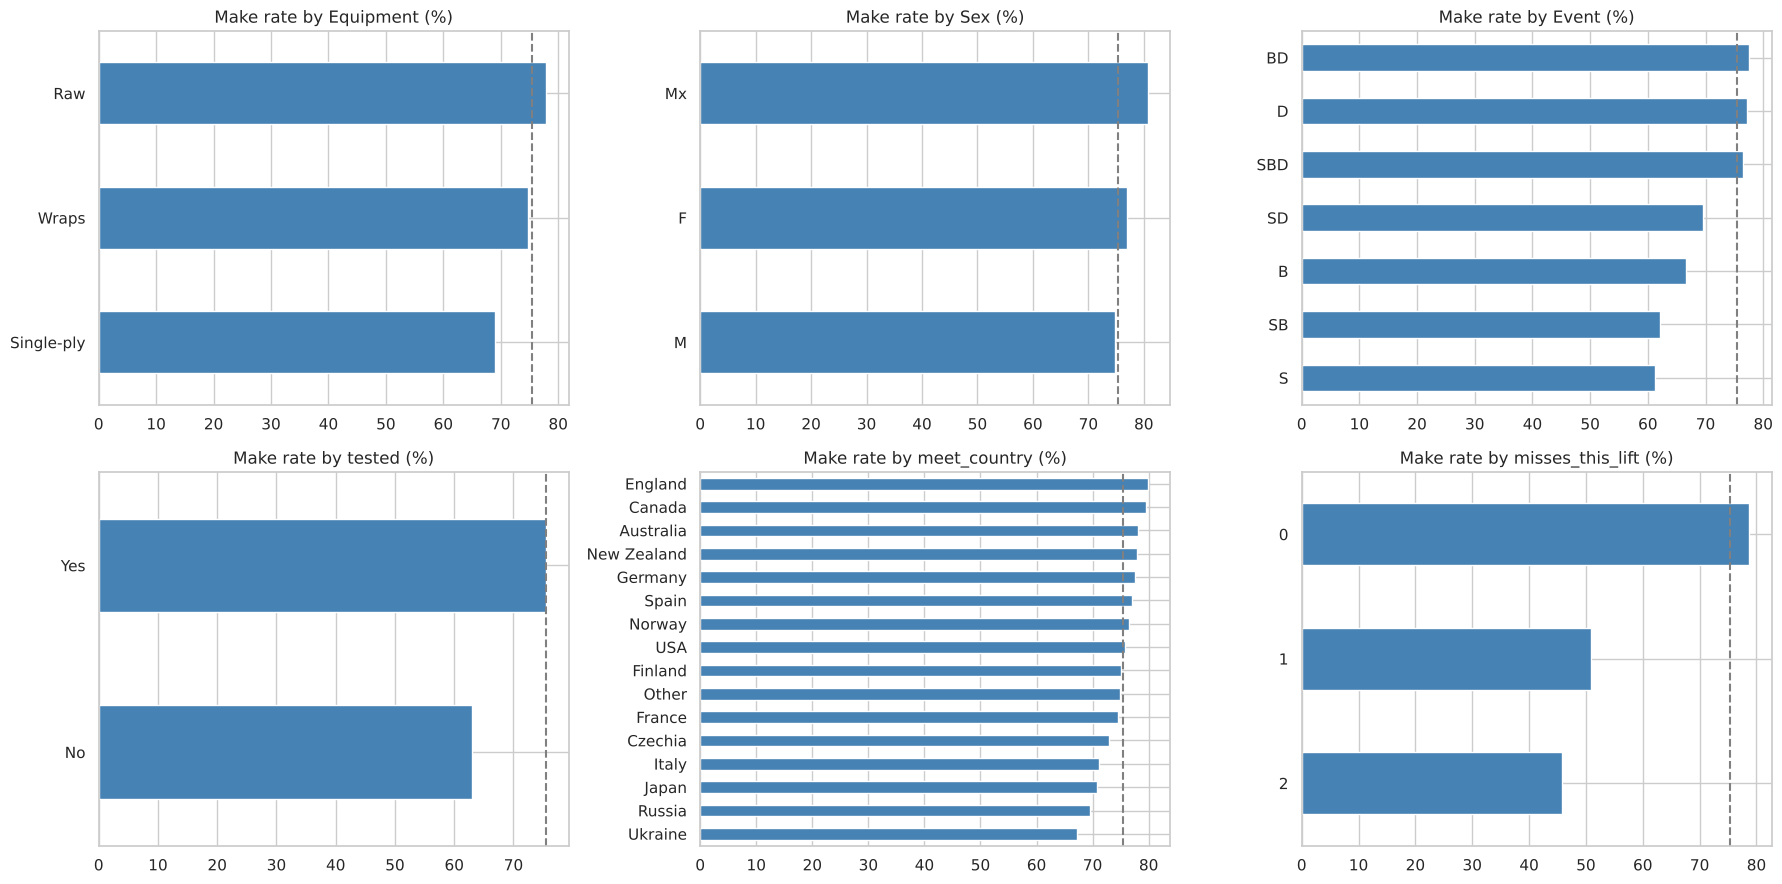

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, ['Equipment', 'Sex', 'Event', 'tested', 'meet_country', 'misses_this_lift']):
    rate = (attempts.groupby(col, observed=True)['made'].mean() * 100).sort_values()
    rate.plot(kind='barh', ax=ax, color='steelblue')
    ax.axvline(overall * 100, color='grey', ls='--')
    ax.set_title(f'Make rate by {col} (%)')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

In [12]:
rows = []
for col in ['lift', 'attempt_no', 'prev_result', 'misses_this_lift', 'misses_earlier_lifts',
            'Equipment', 'Sex', 'Event', 'tested', 'meet_country', 'Federation']:
    stats = attempts.groupby(col, observed=True)['made'].agg(['mean', 'size'])
    stats = stats[stats['size'] >= 1000]                 # ignore tiny groups
    rows.append({'feature': col, 'lowest_%': round(stats['mean'].min() * 100, 1),
                 'highest_%': round(stats['mean'].max() * 100, 1),
                 'spread_points': round((stats['mean'].max() - stats['mean'].min()) * 100, 1),
                 'levels': attempts[col].nunique()})
pd.DataFrame(rows).sort_values('spread_points', ascending=False).reset_index(drop=True)

,feature,lowest_%,highest_%,spread_points,levels
0,prev_result,50.1,90.0,39.9,4
1,attempt_no,54.8,90.0,35.1,3
2,misses_earlier_lifts,42.7,76.1,33.4,7
3,misses_this_lift,45.8,78.7,32.9,3
4,Federation,60.2,83.5,23.2,108
5,Event,61.2,77.6,16.3,7
6,meet_country,67.2,79.8,12.6,16
7,tested,63.0,75.5,12.5,2
8,lift,70.9,80.0,9.1,3
9,Equipment,69.0,77.9,8.9,3


The **spread** (highest minus lowest make rate across a column's levels, groups of 1,000+ attempts) ranks how strongly
each categorical feature separates made from missed attempts.

- **`prev_result`** is the strongest: after a **miss**, the next attempt on that lift is made only **50.1%** of the time, against 70.9% after a make (first attempts: 90.0%).
- **`attempt_no`**: openers are made 86.7–94.9% of the time; third attempts only **46.5% on bench**, 57.9% on deadlift and 63.1% on squat.
- **`misses_this_lift`**: 78.7% with no miss so far on the lift, 50.9% after one, 45.8% after two.
- **`misses_earlier_lifts`**: drops slowly from 76.1% (no earlier misses) to 69.0% after 4; a lifter having a bad day carries it into the next lift.
- **`Federation`** spreads 23 points (60.2% to 83.5%) but has 108 levels and overlaps with `meet_country`, so only `meet_country` (top 15 + Other) is kept.
- **`Event`**: bench-only meets (66.7%) are harder than full power (76.5%); **`Equipment`**: single-ply 69.0% vs raw 77.9%. **`Sex`** barely matters (74.7% vs 76.9%).

## 8. Does the make rate change over time?

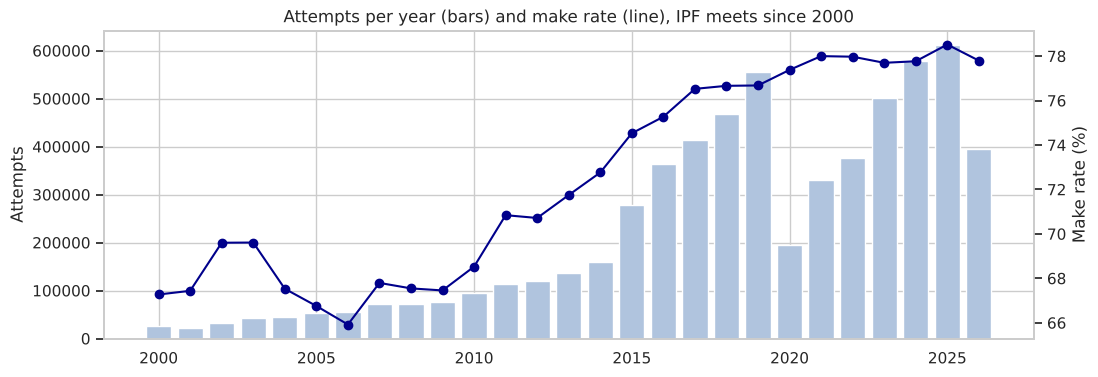

,attempts,make_rate
year,,
2015,277273,74.5
2016,363853,75.3
2017,414670,76.5
2018,468423,76.7
2019,555144,76.7
2020,194416,77.4
2021,330955,78.0
2022,376442,78.0
2023,501022,77.7


In [13]:
yearly = attempts.groupby('year').agg(attempts=('made', 'size'), make_rate=('made', 'mean'))
yearly = yearly[yearly.index >= 2000]
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.bar(yearly.index, yearly['attempts'], color='lightsteelblue', label='attempts')
ax1.set_ylabel('Attempts')
ax2 = ax1.twinx()
ax2.plot(yearly.index, yearly['make_rate'] * 100, color='darkblue', marker='o', label='make rate %')
ax2.set_ylabel('Make rate (%)'); ax2.grid(False)
plt.title('Attempts per year (bars) and make rate (line), IPF meets since 2000')
plt.show()
yearly.tail(12).assign(make_rate=lambda t: (t['make_rate'] * 100).round(1))

The make rate has **risen slowly**, from 74.5% in 2015 to 77.8–78.5% since 2021, while the number of attempts per year has grown (with a dip in 2020).
Meets before 2024 make 74.6% of attempts and meets from 2024 onward 78.1%. This drift is why the model is trained on **earlier meets and tested on later ones** (notebook 03): it shows how the model would do on future meets, not on a random mix of old and new.

## 9. Jump size on the third attempt: correlation is not causation

In [14]:
third = attempts[(attempts['attempt_no'] == 3) & (attempts['prev_result'] == 'made')]
jump_rate = third.groupby(pd.cut(third['jump_pct'], [0, 1.5, 2.5, 3.5, 5, 7.5, 10, 40]), observed=True)['made'].agg(['count', 'mean']).round(3)
jump_rate

,count,mean
jump_pct,,
"(0.0, 1.5]",38252,0.497
"(1.5, 2.5]",209722,0.539
"(2.5, 3.5]",280408,0.577
"(3.5, 5.0]",517827,0.598
"(5.0, 7.5]",418930,0.606
"(7.5, 10.0]",157021,0.570
"(10.0, 40.0]",94143,0.540


Among third attempts after a **made** second attempt, the smallest jumps (up to 1.5%) are made only **49.7%** of the time, rising to 60.6% for 5–7.5% jumps, then falling again for very big jumps (54.0% above 10%).

A smaller jump should be *easier*, so why is it missed more? Lifters choose a tiny jump when the second attempt was **slow and hard**: the jump is a sign of a struggling lifter, not the cause of the miss.
The data cannot see how the previous attempt moved. A model will learn "small jump → likely miss", and its predictions must be read as **"attempts like this one were made X% of the time"**, not as advice that a lighter weight is harder.
Measuring bar speed from video is what the computer-vision part of the project could add.

## 10. Which features are most correlated with the target, and with each other?

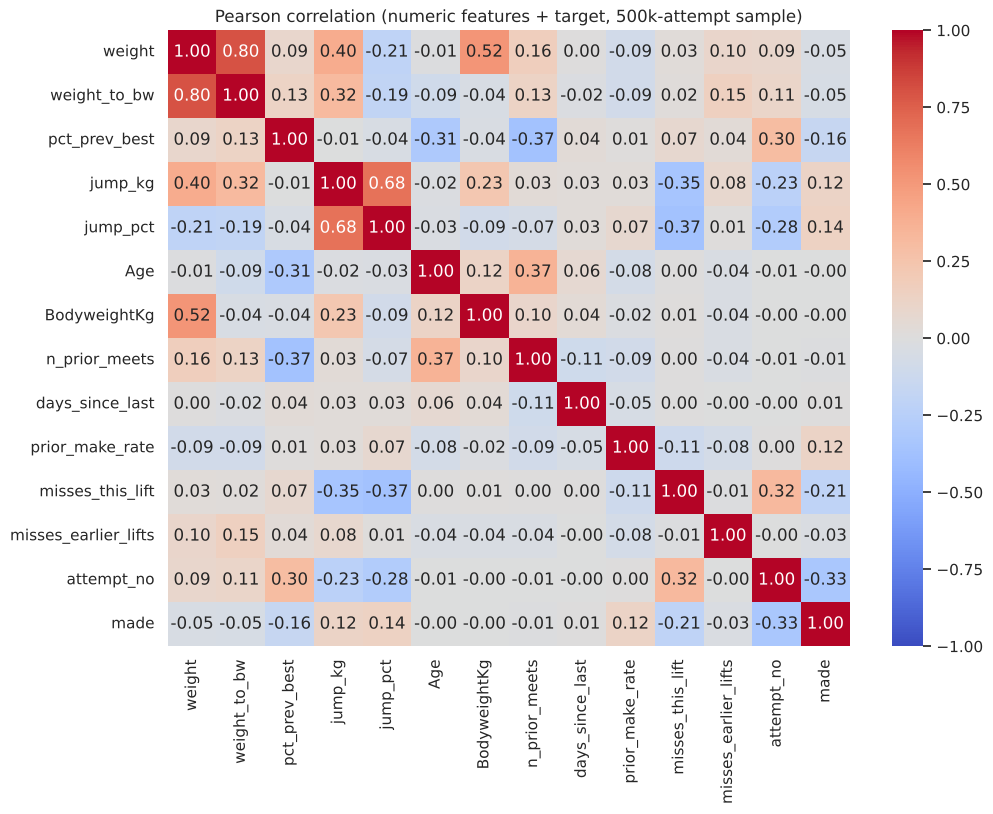

In [15]:
corr_cols = [c for c in numeric if c != 'attempt_no'] + ['attempt_no']
corr = sample[corr_cols + ['made']].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Pearson correlation (numeric features + target, 500k-attempt sample)')
plt.show()

In [16]:
target_corr = pd.DataFrame({
    'pearson': sample[corr_cols].corrwith(sample['made']),
    'spearman': sample[corr_cols].corrwith(sample['made'], method='spearman'),
}).round(3).sort_values('spearman', key=abs, ascending=False)
target_corr

,pearson,spearman
attempt_no,-0.333,-0.332
misses_this_lift,-0.206,-0.211
pct_prev_best,-0.161,-0.204
jump_pct,0.136,0.179
jump_kg,0.118,0.163
prior_make_rate,0.118,0.120
weight_to_bw,-0.052,-0.041
weight,-0.047,-0.038
misses_earlier_lifts,-0.029,-0.023
days_since_last,0.006,0.011


In [17]:
pairs = corr.drop(index='made', columns='made').abs().where(np.triu(np.ones((len(corr_cols), len(corr_cols)), dtype=bool), k=1))
pairs.stack().sort_values(ascending=False).head(6).round(2)

weight         weight_to_bw        0.80
jump_kg        jump_pct            0.68
weight         BodyweightKg        0.52
               jump_kg             0.40
jump_pct       misses_this_lift    0.37
pct_prev_best  n_prior_meets       0.37
dtype: float64

- The strongest linear links with the target: `attempt_no` (−0.33), `misses_this_lift` (−0.21), `pct_prev_best` (Spearman −0.20), `jump_pct` (+0.18) and `prior_make_rate` (+0.12). Profile features (age, bodyweight, number of meets) are close to 0 on their own.
- **Multicollinearity:** `weight` and `weight_to_bw` correlate at 0.80, and `jump_kg` and `jump_pct` at 0.68. They carry overlapping information, so the linear model keeps only `weight_to_bw` and the jump bins; trees can use all of them.
- Correlations are small because the effects are non-linear (section 6) and work together (a heavy third attempt after a miss), which is why tree models are expected to do better.

## 11. Leakage check: result columns

The raw file also has `Best3SquatKg`, `TotalKg`, `Place` and the points scores. They look like great predictors, but they are
**calculated from the attempts themselves**, so they are only known after the lift. Example: the best squat compared with the third squat attempt.

In [18]:
raw = load_raw(usecols=['Date', 'ParentFederation', 'Squat3Kg', 'Best3SquatKg'])
raw = raw[(raw['ParentFederation'] == 'IPF') & raw['Squat3Kg'].notna() & raw['Best3SquatKg'].notna()]
third_made = raw['Squat3Kg'] > 0
best_equals_third = raw['Best3SquatKg'] == raw['Squat3Kg'].abs()
print(pd.crosstab(third_made.map({True: '3rd squat made', False: '3rd squat missed'}),
                  best_equals_third.map({True: 'best = 3rd attempt', False: 'best < 3rd attempt'}),
                  rownames=[''], colnames=['']))
print(f'\nIf the best squat equals the 3rd attempt weight, the 3rd attempt was made in {third_made[best_equals_third].mean():.1%} of cases.')
del raw

                  best < 3rd attempt  best = 3rd attempt
                                                        
3rd squat made                     0              414078
3rd squat missed              228694                   0

If the best squat equals the 3rd attempt weight, the 3rd attempt was made in 100.0% of cases.


`Best3SquatKg` gives away the answer almost perfectly, because it **is** the result. The same holds for `TotalKg` (empty when a lift is
failed), `Place` (DQ) and the points scores. None of them are used as features: the model may only use what is known **before** the lifter walks out.

## 12. EDA summary

| Finding | Number | What it means for modeling |
| --- | --- | --- |
| Target balance | 75.4% made / 24.6% missed | ROC-AUC, balanced accuracy, recall for missed; compare imbalance handling |
| Attempt number | 3rd attempts: bench 46.5%, deadlift 57.9%, squat 63.1% | `attempt_no` and `lift` are core features |
| Previous attempt missed | 50.1% vs 70.9% after a make | `prev_result`, `misses_this_lift` |
| Weight vs earlier best | 85.9% at 90–95% → 67.2% at 100–102.5% → 61.4% at 110%+ | Strongest numeric signal; non-linear → bins for the linear model |
| Jump size | ≤0%: 47.3%, 0–2.5%: 55.2%, 5–10%: 75–76% | Non-linear → bins; read as a sign of a hard previous attempt, not a cause |
| Earlier make rate | 63.0% (≤50%) → 82.2% (>89%) | `prior_make_rate` |
| Bad day on earlier lifts | 76.1% → 69.0% after 4 misses | `misses_earlier_lifts` |
| Equipment / event | Single-ply 69.0% vs raw 77.9%; bench-only 66.7% | Keep `Equipment`, `Event` |
| Structural nulls | jump 34.0% (openers), history 26–31% (first meet) | Median + missing flag; "first attempt" / "no history" bins |
| Multicollinearity | weight ~ weight_to_bw 0.80, jump_kg ~ jump_pct 0.68 | Linear model uses one of each pair |
| Time drift | 74.6% before 2024 vs 78.1% from 2024 | Train on earlier meets, test on later meets |
| Leakage | `Best3…Kg` = 3rd attempt ⇔ made (100%) | Never use result columns |